In [1]:
# import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import svm








In [2]:
# load dataset
diabetes=pd.read_csv('/content/diabetes_dataset.csv')

In [3]:
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
diabetes.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [5]:
diabetes.shape

(768, 9)

In [6]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [7]:
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
diabetes.value_counts('Outcome')

,count
Outcome,
0,500
1,268


0--> non diabetic
1--> diabetic

In [9]:
diabetes.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


In [10]:
x=diabetes.drop(columns='Outcome',axis=1)
y=diabetes['Outcome']

In [11]:
# standardization
scalar=StandardScaler()

In [12]:
scalar.fit(x)

StandardScaler()

In [13]:
standardized_data=scalar.transform(x)

In [14]:
print(standardized_data)

[[ 0.63994726  0.84832379  0.14964075 ...  0.20401277  0.46849198
   1.4259954 ]
 [-0.84488505 -1.12339636 -0.16054575 ... -0.68442195 -0.36506078
  -0.19067191]
 [ 1.23388019  1.94372388 -0.26394125 ... -1.10325546  0.60439732
  -0.10558415]
 ...
 [ 0.3429808   0.00330087  0.14964075 ... -0.73518964 -0.68519336
  -0.27575966]
 [-0.84488505  0.1597866  -0.47073225 ... -0.24020459 -0.37110101
   1.17073215]
 [-0.84488505 -0.8730192   0.04624525 ... -0.20212881 -0.47378505
  -0.87137393]]


In [15]:
x=standardized_data

In [16]:
train_x,test_x,train_y,test_y=train_test_split(x,y,test_size=0.2,stratify=y,random_state=2)

In [17]:
classifier=svm.SVC(kernel='linear')

In [18]:
classifier.fit(train_x,train_y)

SVC(kernel='linear')

In [19]:
# accuracy check on training data
training_data_prediction=classifier.predict(train_x)
accuracy=accuracy_score(training_data_prediction,train_y)
print('accuracy on training data: ',accuracy)

accuracy on training data:  0.7866449511400652


In [20]:
# accuracy on testing data
testing_data_prediction=classifier.predict(test_x)
accuracy=accuracy_score(testing_data_prediction,test_y)
print('accuracy on testing data: ',accuracy)

accuracy on testing data:  0.7727272727272727


In [21]:
# make model
input=(1,85,66,29,0,26.6,0.351,31)
input_as_array=np.asarray(input)
input_reshaped=input_as_array.reshape(1,-1)
# apply standardization
std_data=scalar.transform(input_reshaped)
prediction=classifier.predict(std_data)
if prediction[0]==0:
  print('non diabetic')
else:
  print('diabetic')

non diabetic


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


# **visualize tha dataset for increase the accuracy of model**

Text(0, 0.5, 'Insulin')

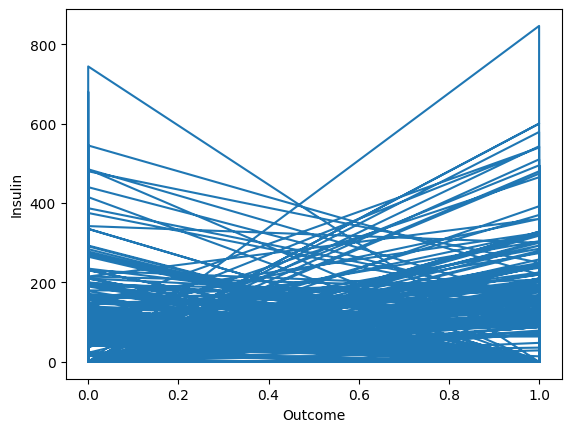

In [27]:
plt.plot(diabetes['Outcome'],diabetes['Insulin'])
plt.xlabel('Outcome')
plt.ylabel('Insulin')

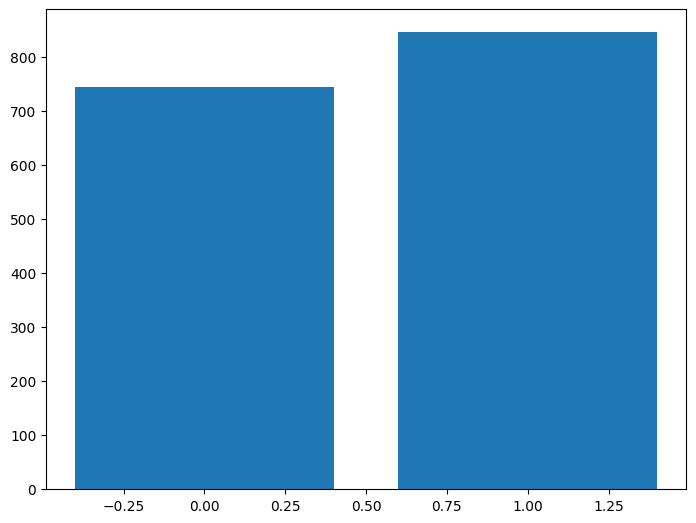

In [28]:
fig=plt.figure()
ax=fig.add_axes([0,0,1,1])
ax.bar(diabetes['Outcome'],diabetes['Insulin'])
plt.show()